# DATA 37711 — Homework 2

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import norm

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(8)
DEVICE = "cpu"   
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

### I have manually written out the mathematical derivations, which are available in a separate file in this GitHub repository.

---
# Problem 1

## 1(a) Link function

Let $g(x)=(g_1(x),g_2(x))\in\mathbb R^2$. The mean can be any real number, so I use the **identity link** for it. The standard deviation has to be strictly positive, so **ReLU** is considered. However, **ReLU** can output zero so that the better choice would be **Softplus**. 

$$f_\mu(x)=g_1(x),\qquad f_\sigma(x)=\operatorname{softplus}(g_2(x))+\varepsilon=\log\!\big(1+e^{g_2(x)}\big)+\varepsilon ,$$

## 1(b) Loss function

Under $Y\mid X=x\sim\mathcal N(f_\mu(x),f_\sigma(x)^2)$, the **Gaussian negative log-likelihood** of the data is the loss:

$$\mathcal L(\theta)=\frac1n\sum_{i=1}^n\left[\log f_\sigma(x_i)+\frac{(y_i-f_\mu(x_i))^2}{2f_\sigma(x_i)^2}\right]+\tfrac12\log(2\pi).$$


## 1(c) MLP with mean and standard-deviation outputs on the NYC taxi data

### Data and split

80, 10, 10 train-val-test split

In [39]:
taxi = pd.read_parquet("taxi_trips.parquet")
target = taxi['trip_duration']
X = taxi.drop(columns=['trip_duration'])
print(X.shape, target.shape)

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(taxi))
train, tval, ttest = np.split(idx, [int(.8*len(taxi)), int(.9*len(taxi))])

X_train, y_train = X.iloc[train], target.iloc[train]
X_val, y_val = X.iloc[tval], target.iloc[tval]
X_test, y_test = X.iloc[ttest], target.iloc[ttest]

print(X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape)


(523554, 7) (523554,)
(418843, 7) (52355, 7) (52356, 7) (418843,) (52355,) (52356,)


### Evaluation helpers

In [40]:
def gaussian_nll(y, mu, sigma):
    return -norm.logpdf(y, loc=mu, scale=sigma).mean()

def evaluate_gaussian(name, y, mu, sigma):
    z = norm.ppf(0.95)
    return dict(
        model=name,
        nll=gaussian_nll(y, mu, sigma),
        mse=((y - mu) ** 2).mean(),
        mae=np.abs(y - mu).mean(),
        coverage=(y <= mu + z * sigma).mean(),)

### Baselines
**Linear regression + constant σ** — OLS for $\mu(x)$, $\sigma$ = residual SD on the training set.


In [41]:
from sklearn.linear_model import LinearRegression

baseline = {}
lin = LinearRegression().fit(X_train, y_train)
sd_lin = np.std(y_train - lin.predict(X_train))
baseline["Linear + const σ"] = lambda X: (lin.predict(X), np.full(len(X), sd_lin))

### The model

In [42]:
class GaussianMLP(nn.Module):
    def __init__(self, d_in, hidden=(256, 256, 128), min_sigma=1e-3):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, 2)
        self.min_sigma = min_sigma

    def forward(self, x):
        out = self.head(self.body(x))
        mu = out[:, 0]                                       
        sigma = F.softplus(out[:, 1]) + self.min_sigma       
        return mu, sigma


def nll_loss(y, mu, sigma):
    return (torch.log(sigma) + 0.5 * ((y - mu) / sigma) ** 2).mean()


def mse_loss(y, mu):
    return ((y - mu) ** 2).mean()


y_mean, y_std = float(y_train.mean()), float(y_train.std())
to_t = lambda a: torch.from_numpy(np.ascontiguousarray(a)).to(DEVICE) # TO TENSORS
X_train_t, X_val_t, X_test_t = to_t(X_train), to_t(X_val), to_t(X_test)
y_train_t, y_val_t = to_t((y_train - y_mean) / y_std), to_t((y_val - y_mean) / y_std)


# patience allowed consecutive epochs without improvement before stopping early
def train_taxi(loss_fn, epochs=40, batch=2048, lr=1e-3, patience=5, seed=SEED):
    torch.manual_seed(seed)
    model = GaussianMLP(X_train_t.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed) # random permutation generator for shuffling batches
    best, best_state, bad, hist = np.inf, None, 0, [] # bad is the number of consecutive epochs without improvement; hist is a list of (train_loss, val_loss) tuples
    for ep in range(epochs):
        model.train()
        p = torch.randperm(len(X_train_t), generator=g)
        tot = 0.0 # initial training loss for this epoch
        for i in range(0, len(p), batch):
            idx = p[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(y_train_t[idx], *model(X_train_t[idx]))
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            va = loss_fn(y_val_t, *model(X_val_t)).item()
        hist.append((tot / len(p), va))
        if va < best - 1e-5:
            best, bad = va, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()} # v.clone() is important to avoid storing references to the model's parameters, which will change in subsequent epochs
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    print(f"stopped after {ep + 1} epochs, best val loss {best:.4f}")
    return model, np.array(hist)


@torch.no_grad()
def predict_taxi(model, X_t):
    mu, sigma = model(X_t)
    return y_mean + y_std * mu.numpy(), y_std * sigma.numpy()

In [43]:
%%time
gauss_mlp, hist_nll = train_taxi(nll_loss)

stopped after 22 epochs, best val loss -0.3462
CPU times: user 10 s, sys: 3.38 s, total: 13.4 s
Wall time: 8.85 s


### Test-set results (Gaussian predictive distribution)

In [44]:
preds_te = {name: f(X_test) for name, f in baseline.items()}
preds_te["Gaussian MLP (ours)"] = predict_taxi(gauss_mlp, X_test_t)
res1c = pd.DataFrame([evaluate_gaussian(k, y_test, *v) for k, v in preds_te.items()]).set_index("model")
res1c

,nll,mse,mae,coverage
model,,,,
Linear + const σ,3.4368,56.5836,5.5867,0.9410
Gaussian MLP (ours),2.6486,14.7271,2.4499,0.9514


### 1(c) Results and discussion

**Setup.** We use a random 80/10/10 split (419k / 52.4k / 52.4k trips). The model is an MLP with hidden layers 7 → 256 → 256 → 128 and a 2-dimensional output, using the identity link for $\mu$ and the softplus link for $\sigma$. It is trained with the Gaussian NLL from 1(b) using Adam, with early stopping on validation NLL. The best validation epoch was reached after about 20 epochs.

- The Gaussian MLP significantly outperforms the linear baseline in both prediction accuracy and uncertainty estimation. Trip duration depends strongly and non-linearly on the pickup/dropoff geometry, which a linear model cannot capture.
- NLL: The Gaussian MLP has a lower negative log-likelihood, suggesting it provides a better fit to the observed trip durations while accounting for uncertainty.
- MSE: The Gaussian MLP reduces mean squared error by approximately 74%, indicating significantly fewer large prediction errors.
- MAE: The Gaussian MLP reduces mean absolute error by approximately 56%, meaning its predictions are much closer to the actual trip durations on average.
- Coverage: The Gaussian MLP achieves 95.14% coverage, very close to the expected 95%, suggesting its prediction intervals are reasonably calibrated on the test data.

## 1(d) Probability that a trip takes less than 45 minutes

Given the fitted $\hat\mu(x)=f_\mu(x)$ and $\hat\sigma(x)=f_\sigma(x)$, the predictive distribution is $\mathcal N(\hat\mu(x),\hat\sigma(x)^2)$. Its CDF at 45 gives

$$\widehat P(Y<45\mid X=x)=\Phi\!\left(\frac{45-\hat\mu(x)}{\hat\sigma(x)}\right),$$

## 1(e) Probability that a trip takes less than 45 minutes — test-set evaluation

In [45]:
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

T = 45.0
lab_te = (y_test < T).astype(int)
print(f"fraction of test trips < 45 min: {lab_te.mean():.4f}")

def prob_below(mu, sigma, t=T):
    return norm.cdf((t - mu) / sigma)          # P(Y < t | x) under N(mu, sigma^2)

probs = {"Base rate (constant p)": np.full(len(y_test), (y_train < T).mean())}
for name, (mu, sd) in preds_te.items():
    probs[name] = prob_below(mu, sd)

eps = 1e-7
rows = []
for name, p in probs.items():
    p = np.clip(p, eps, 1 - eps)
    rows.append(dict(model=name,
                     Brier=brier_score_loss(lab_te, p),
                     LogLoss=log_loss(lab_te, p, labels=[0, 1]),
                     Accuracy=float(np.mean((p >= 0.5) == lab_te)),
                     AUC=roc_auc_score(lab_te, p) if p.std() > 0 else 0.5,
                     n_pred_ge45=int(np.sum(p < 0.5))))
res1e = pd.DataFrame(rows).set_index("model")
res1e

fraction of test trips < 45 min: 0.9955


,Brier,LogLoss,Accuracy,AUC,n_pred_ge45
model,,,,,
Base rate (constant p),0.0044,0.0286,0.9955,0.5000,0
Linear + const σ,0.0045,0.0473,0.9955,0.8304,0
Gaussian MLP (ours),0.0032,0.0194,0.9963,0.9384,149


### 1(e) Evaluation of $\widehat P(Y<45)$ on the test set

- **The task is highly imbalanced.** 99.55% of test trips take less than 45 minutes, so the trivial rule "always predict < 45" already has 99.55% accuracy. Accuracy at the 0.5 threshold is therefore a weak metric here. All models land between 99.55% and 99.63%, and the improvement comes from correctly flagging a few of the rare long trips.
- **Proper scoring rules are more informative.** The Gaussian MLP model has better **log-loss (0.0194)** It also has better ranking of trips (AUC 0.94) and Brier score. 
- The constant-σ baselines that ignore or barely use $x$ are *worse* than the base rate on log-loss. Their Gaussian tails are badly mis-specified at the 45-minute threshold.

---
# Problem 2

In [46]:
retail = pd.read_csv("retail.csv")
retail["StockCode"] = retail["StockCode"].astype(str).astype("category")
retail["CustomerID"] = retail["CustomerID"].astype(int).astype(str).astype("category")
CATS = ["StockCode", "CustomerID"]
print(retail.dtypes, retail.shape)
retail.head()
retail.isnull().sum()

Quantity         int64
StockCode     category
CustomerID    category
dtype: object (397924, 3)


Quantity      0
StockCode     0
CustomerID    0
dtype: int64

## 2(a) Cardinality

In [47]:
card = retail[CATS].nunique()
print("unique values:\n", card.to_string())

unique values:
 StockCode     3665
CustomerID    4339


**One-hot encoding** is not feasible, since the unique values for each category is too many which will generates too many extra columns. Due to this high cardinality, I will the target encoding. 

In [48]:
# Data splitting
rng = np.random.default_rng(SEED)
idx = rng.permutation(len(retail))
train, tval, ttest = np.split(idx, [int(.8*len(retail)), int(.9*len(retail))])  
target = retail['Quantity']
X = retail.drop(columns=['Quantity'])

X_train, y_train = X.iloc[train], target.iloc[train]
X_val, y_val = X.iloc[tval], target.iloc[tval]
X_test, y_test = X.iloc[ttest], target.iloc[ttest]

print(X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape)

(318339, 2) (39792, 2) (39793, 2) (318339,) (39792,) (39793,)


In [49]:
X_train.head()

,StockCode,CustomerID
392335,22475,17861
64783,22665,13870
271042,21070,13263
270868,21894,14056
246614,84510A,14769


## 2(b) Target encoding + gradient-boosted trees

**Leakage.** If the encoder is fit on the same rows the downstream model is trained on, each row's own target leaks into its feature (badly for levels with few rows), and the model learns to over-trust the encoding. We therefore use **5-fold out-of-fold target encoding** for the training rows; validation and test rows are encoded with an encoder fit on the full training set. 

Here for this question. I did not use `category encoders` package since I found `sklearn` is easier in its code. 

In [50]:
from sklearn.preprocessing import TargetEncoder

encoder = TargetEncoder(target_type='continuous', random_state = SEED) # need to create the encoder first then the train data can be used to fit it and then later val and test set can used this fitted encoder
X_train_encoded = encoder.fit_transform(X_train, y_train)
X_val_encoded = encoder.transform(X_val)
X_test_encoded = encoder.transform(X_test)
pd.DataFrame(X_train_encoded, columns=[f"TE_{c}" for c in CATS]).describe()


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


,TE_StockCode,TE_CustomerID
count,318339.0000,318339.0000
mean,12.6137,12.4560
std,11.6698,25.6291
min,1.0000,1.0000
25%,6.4215,3.8782
50%,10.0750,8.2599
75%,15.4217,12.8667
max,1300.0000,3186.0000


**EDA & Feature Engineering**

In [51]:
(retail["Quantity"] == 0).sum()

np.int64(0)

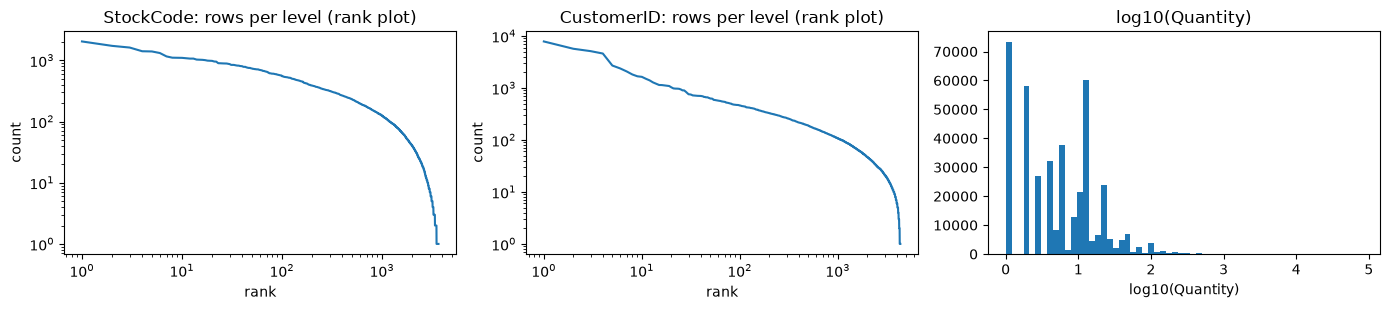

In [52]:
counts = {c: retail[c].value_counts() for c in CATS}
q = retail["Quantity"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for a, c in zip(ax[:2], CATS):
    a.loglog(np.arange(1, len(counts[c]) + 1), counts[c].values); a.set(title=f"{c}: rows per level (rank plot)", xlabel="rank", ylabel="count")
ax[2].hist(np.log10(q), bins=60); ax[2].set(title="log10(Quantity)", xlabel="log10(Quantity)")
plt.tight_layout(); plt.show()

**Gradient Boosting Model Comparison**

Four `GradientBoostingRegressor` configurations were evaluated to examine the effects of loss function and target transformation on predicting the heavily right-skewed Quantity target. I did not try on tranforming features since, for tree-based Gradient Bossting, taking the log of positive numberical features often changes the numberical thresholds but not the underly tree partitions (ordering of numerical features) so that teh final evaluation metrics will remain unchanged. 

In [53]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

results = {}

# Model 1: MSE on original target
m1 = GradientBoostingRegressor(
    loss="squared_error",
    random_state=SEED
)
m1.fit(X_train_encoded, y_train)
results["MSE"] = m1.predict(X_val_encoded)

# Model 2: Huber on original target
m2 = GradientBoostingRegressor(
    loss="huber",
    random_state=SEED
)
m2.fit(X_train_encoded, y_train)
results["Huber"] = m2.predict(X_val_encoded)

# Model 3: MSE on log-transformed target
m3 = GradientBoostingRegressor(
    loss="squared_error",
    random_state=SEED
)
m3.fit(X_train_encoded, np.log10(y_train))

results["Log-MSE"] = np.power(10, m3.predict(X_val_encoded))

# Model 4: Huber on log-transformed target
m4 = GradientBoostingRegressor(
    loss="huber",
    random_state=SEED
)
m4.fit(X_train_encoded, np.log10(y_train))

results["Log-Huber"] = np.power(10, m4.predict(X_val_encoded))

for name, pred in results.items():
    print(
        name,
        "RMSE:", root_mean_squared_error(y_val, pred),
        "MAE:", mean_absolute_error(y_val, pred),
        "Huber:", np.mean(np.where(np.abs(pred - y_val) <= 1, 0.5 * (pred - y_val) ** 2, np.abs(pred - y_val) - 0.5))
    )

MSE RMSE: 28.358302221535798 MAE: 7.585997085050732 Huber: 7.1268542211439545
Huber RMSE: 28.177083074437334 MAE: 6.777256452926351 Huber: 6.318698488449693
Log-MSE RMSE: 28.47659203134237 MAE: 6.728912306058119 Huber: 6.281766737493795
Log-Huber RMSE: 27.57251937708701 MAE: 6.666283499799603 Huber: 6.220705120704581


In this case, I will Huber as the loss function and log the target for final evalution metrics for the test set (using m4). It gets the lowest in all RMSE, MAE abd Huber loss. 

In [54]:
def evaluate_model(model, X, y):
    y_pred = model.predict(X)
    return dict(model = model, 
                RMSE = np.sqrt(np.mean((y_pred - y) ** 2)),
                MAE = np.mean(np.abs(y_pred - y)),
                R2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2),
                Huber = np.mean(np.where(np.abs(y_pred - y) <= 1, 0.5 * (y_pred - y) ** 2, np.abs(y_pred - y) - 0.5)))

In [55]:
results = evaluate_model(m4, X_test_encoded, y_test)
print(results)

{'model': GradientBoostingRegressor(loss='huber', random_state=0), 'RMSE': np.float64(41.287651451605726), 'MAE': np.float64(11.72833536376609), 'R2': np.float64(-0.07790322620234114), 'Huber': np.float64(11.242167451306063)}


## 2(c) Neural network with an embedding layer per feature

Based on an artical for **Google for Developers**, the general rule of thumb is $$d = n^{0.25}$$

There are 3665 unique values and 4339 unique values for StockCode and CustomerID. According to this rule of thumb, I will use dim = 8 for each of them. 

In [56]:
cat1_mapping = {cat: idx+1 for idx, cat in enumerate(X_train['StockCode'].dropna().unique())}
cat2_mapping = {cat: idx+1 for idx, cat in enumerate(X_train['CustomerID'].dropna().unique())}

X_train_map = X_train.copy() # sace the copy first and then do the map
X_val_map = X_val.copy()
X_test_map = X_test.copy()

for df in (X_train_map, X_val_map, X_test_map):
    df['StockCode']  = df['StockCode'].astype(str).map(cat1_mapping).fillna(0).astype(int)
    df['CustomerID'] = df['CustomerID'].astype(str).map(cat2_mapping).fillna(0).astype(int)
    
embed_dim = 8
n_cat1 = len(cat1_mapping) + 1
n_cat2 = len(cat2_mapping) + 1

In [57]:
class EmbeddingNet(nn.Module):
    def __init__(self, n_cat1, n_cat2, embed_dim=8, dropout=0.1):
        super().__init__()
        self.emb_dim = embed_dim
        self.emb1 = nn.Embedding(n_cat1, self.emb_dim)
        self.emb2 = nn.Embedding(n_cat2, self.emb_dim)

        self.mlp = nn.Sequential(
            nn.Linear(2 * self.emb_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x1 = self.emb1(x[:, 0])
        x2 = self.emb2(x[:, 1])
        return self.mlp(torch.cat([x1, x2], dim=1))

In [58]:
len(X_train)

318339

In [59]:

import copy
import numpy as np
import torch
import torch.nn as nn

def train_model(model, train_loader, val_loader,
                lr=1e-3, epochs=100, patience=10):

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_counter = 0

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # Training
        model.train()
        train_loss = 0.0

        for batch in train_loader:
            *X_batch, y_batch = batch

            optimizer.zero_grad()

            pred = model(*X_batch)
            loss = loss_fn(pred.view(-1), y_batch.view(-1))

            loss.backward()
            optimizer.step()  # update parameters

            train_loss += loss.item() * len(y_batch)

        train_loss /= len(train_loader.dataset)  # average training loss

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for batch in val_loader:
                *X_batch, y_batch = batch

                pred = model(*X_batch)
                loss = loss_fn(pred.view(-1), y_batch.view(-1))

                val_loss += loss.item() * len(y_batch)

        val_loss /= len(val_loader.dataset)  # average validation loss

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # Early stopping
        # Stop when validation loss stops improving
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    # Restore the best model
    model.load_state_dict(best_state)

    return model, train_losses, val_losses, best_epoch


In [60]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.tensor(
    X_train_map[["StockCode", "CustomerID"]].to_numpy(),
    dtype=torch.long
)

X_val_t = torch.tensor(
    X_val_map[["StockCode", "CustomerID"]].to_numpy(),
    dtype=torch.long
)

X_test_t = torch.tensor(
    X_test_map[["StockCode", "CustomerID"]].to_numpy(),
    dtype=torch.long
)

y_train_t = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
)

y_val_t = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.float32
)

y_test_t = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
)


# Model 1: Original target
train_dataset_normal = TensorDataset(X_train_t, y_train_t)
val_dataset_normal = TensorDataset(X_val_t, y_val_t)

# Model 2: Log10 target
train_dataset_log = TensorDataset(X_train_t, torch.log10(y_train_t))
val_dataset_log = TensorDataset(X_val_t, torch.log10(y_val_t))

# Create DataLoaders
g_normal = torch.Generator().manual_seed(SEED)
g_log = torch.Generator().manual_seed(SEED)

train_loader_normal = DataLoader(
    train_dataset_normal,
    batch_size=512,
    shuffle=True,
    generator=g_normal
)

val_loader_normal = DataLoader(
    val_dataset_normal,
    batch_size=512,
    shuffle=False
)

train_loader_log = DataLoader(
    train_dataset_log,
    batch_size=512,
    shuffle=True,
    generator=g_log
)

val_loader_log = DataLoader(
    val_dataset_log,
    batch_size=512,
    shuffle=False
)
n_cat1 = int(X_train_map["StockCode"].max()) + 1
n_cat2 = int(X_train_map["CustomerID"].max()) + 1

model_normal = EmbeddingNet(n_cat1=n_cat1, n_cat2=n_cat2, embed_dim=8, dropout=0.1)
model1, train_losses, val_losses, best_epoch = train_model(
    model_normal, train_loader_normal, val_loader_normal, lr=1e-3, epochs=100, patience=10)

model_log = EmbeddingNet(n_cat1=n_cat1, n_cat2=n_cat2, embed_dim=8, dropout=0.1)

model2, train_losses_log, val_losses_log, best_epoch_log = train_model(
    model_log, train_loader_log, val_loader_log, lr=1e-3, epochs=100, patience=10)


In [61]:
def evaluate_model(model, X, y, log_target=False, X_target=None):
    model.eval()

    with torch.no_grad():
        if X_target is None:
            y_pred = model(X).squeeze(-1).cpu().numpy()
        else:
            y_pred = model(X, X_target).squeeze(-1).cpu().numpy()

    if log_target:
        y_pred = np.power(10, y_pred)

    y_true = y.cpu().numpy().reshape(-1)

    errors = y_pred - y_true

    return dict(
        model=model,
        RMSE=np.sqrt(np.mean(errors ** 2)),
        MAE=np.mean(np.abs(errors)),
        R2=1 - np.sum(errors ** 2) /
             np.sum((y_true - np.mean(y_true)) ** 2),
        Huber=np.mean(
            np.where(
                np.abs(errors) <= 1,
                0.5 * errors ** 2,
                np.abs(errors) - 0.5
            )
        )
    )

In [62]:
test_results = evaluate_model(model_normal, X_test_t, y_test_t)
test_results_log = evaluate_model(model_log, X_test_t, y_test_t, log_target=True)

print("Test RMSE:", test_results["RMSE"])
print("Test MAE:", test_results["MAE"])
print("Test R2:", test_results["R2"])
print("Test Huber:", test_results["Huber"])
print("Test RMSE (log target):", test_results_log["RMSE"])
print("Test MAE (log target):", test_results_log["MAE"])
print("Test R2 (log target):", test_results_log["R2"])
print("Test Huber (log target):", test_results_log["Huber"])

Test RMSE: 30.610115
Test MAE: 8.345527
Test R2: 0.40752596
Test Huber: 7.869616
Test RMSE (log target): 29.64135
Test MAE (log target): 5.9849944
Test R2 (log target): 0.4444344
Test Huber (log target): 5.5553894


Below is the result for target encoding model 

In [63]:
print("Test RMSE:", results["RMSE"])
print("Test MAE:", results["MAE"])
print("Test R2:", results["R2"])
print("Test Huber:", results["Huber"])

Test RMSE: 41.287651451605726
Test MAE: 11.72833536376609
Test R2: -0.07790322620234114
Test Huber: 11.242167451306063


### 2(c) Explanation
The embedding neural network trained on the log-transformed target achieves the best test-set performance, with an RMSE of 29.64, MAE of 5.98, R² of 0.44, and Huber loss of 5.56. Compared with the target encoding model, it reduces RMSE by approximately 28.2% and MAE by 49.02%, suggesting that the embedding layer and the archetecture of MLP helps a lot. The log transformation of target also leads to better RMSE, MAE, R2 and Huber loss, suggesting the effectiveness of log transformation of the target in terms of handling heavy tails. Generally, the MLP with the embedding layers performs better than the target encoding method. 

## 2(d) Embeddings **+** target-encoded features

In [64]:
class HybridEmbeddingNet(nn.Module):
    def __init__(self, n_cat1, n_cat2, embed_dim=8,
                 n_target_features=2, dropout=0.1):
        super().__init__()

        self.emb1 = nn.Embedding(n_cat1, embed_dim)
        self.emb2 = nn.Embedding(n_cat2, embed_dim)

        self.mlp = nn.Sequential(
            nn.Linear(2 * embed_dim + n_target_features, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x_cat, x_target):
        x1 = self.emb1(x_cat[:, 0])
        x2 = self.emb2(x_cat[:, 1])

        x = torch.cat([x1, x2, x_target], dim=1)

        return self.mlp(x)

In [65]:
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

# log1p squashes the long tail (values up to ~3186), then standardize with TRAIN stats only
te_train = np.log1p(np.asarray(X_train_encoded))
te_mean, te_std = te_train.mean(axis=0), te_train.std(axis=0) # axis = 0 means computing mean and std along each column (feature)

def scale_te(a):
    return (np.log1p(np.asarray(a)) - te_mean) / te_std

X_train_t_encoded = torch.tensor(scale_te(X_train_encoded), dtype=torch.float32)
X_val_t_encoded   = torch.tensor(scale_te(X_val_encoded),   dtype=torch.float32)
X_test_t_encoded  = torch.tensor(scale_te(X_test_encoded),  dtype=torch.float32)


train_dataset_normal_hybrid = TensorDataset(
    X_train_t, X_train_t_encoded, y_train_t
)

val_dataset_normal_hybrid = TensorDataset(
    X_val_t, X_val_t_encoded, y_val_t
)

train_dataset_log_hybrid = TensorDataset(
    X_train_t, X_train_t_encoded, torch.log10(y_train_t)
)

val_dataset_log_hybrid = TensorDataset(
    X_val_t, X_val_t_encoded, torch.log10(y_val_t)
)

g_normal = torch.Generator().manual_seed(SEED)
g_log = torch.Generator().manual_seed(SEED)

train_loader_normal = DataLoader(
    train_dataset_normal_hybrid,
    batch_size=512,
    shuffle=True,
    generator=g_normal
)

val_loader_normal = DataLoader(
    val_dataset_normal_hybrid,
    batch_size=512,
    shuffle=False
)

train_loader_log = DataLoader(
    train_dataset_log_hybrid,
    batch_size=512,
    shuffle=True,
    generator=g_log
)

val_loader_log = DataLoader(
    val_dataset_log_hybrid,
    batch_size=512,
    shuffle=False
)

n_cat1 = int(X_train_map["StockCode"].max()) + 1
n_cat2 = int(X_train_map["CustomerID"].max()) + 1

model_hybrid1 = HybridEmbeddingNet(
    n_cat1=n_cat1,
    n_cat2=n_cat2,
    embed_dim=8,
    n_target_features=2,
    dropout=0.1
)

model_hybrid2 = HybridEmbeddingNet(
    n_cat1=n_cat1,
    n_cat2=n_cat2,
    embed_dim=8,
    n_target_features=2,
    dropout=0.1
)

model_hybrid1, train_losses_hybrid, val_losses_hybrid, best_epoch_hybrid = train_model(
    model_hybrid1,
    train_loader_normal,
    val_loader_normal,
    lr=1e-3,
    epochs=100,
    patience=10
)

model_hybrid2, train_losses_hybrid_log, val_losses_hybrid_log, best_epoch_hybrid_log = train_model(
    model_hybrid2,
    train_loader_log,
    val_loader_log,
    lr=1e-3,
    epochs=100,
    patience=10
)

In [66]:
test_results_hybrid = evaluate_model(
    model_hybrid1,
    X_test_t,
    y_test_t,
    X_target=X_test_t_encoded
)

test_results_log_hybrid = evaluate_model(
    model_hybrid2,
    X_test_t,
    y_test_t,
    log_target=True,
    X_target=X_test_t_encoded
)
print("Test RMSE:", test_results_hybrid["RMSE"])
print("Test MAE:", test_results_hybrid["MAE"])
print("Test R2:", test_results_hybrid["R2"])
print("Test Huber:", test_results_hybrid["Huber"])
print("Test RMSE (log target):", test_results_log_hybrid["RMSE"])
print("Test MAE (log target):", test_results_log_hybrid["MAE"])
print("Test R2 (log target):", test_results_log_hybrid["R2"])
print("Test Huber (log target):", test_results_log_hybrid["Huber"])

Test RMSE: 28.76084
Test MAE: 7.897519
Test R2: 0.47695082
Test Huber: 7.427784
Test RMSE (log target): 31.137302
Test MAE (log target): 5.940826
Test R2 (log target): 0.38694227
Test Huber (log target): 5.5147033


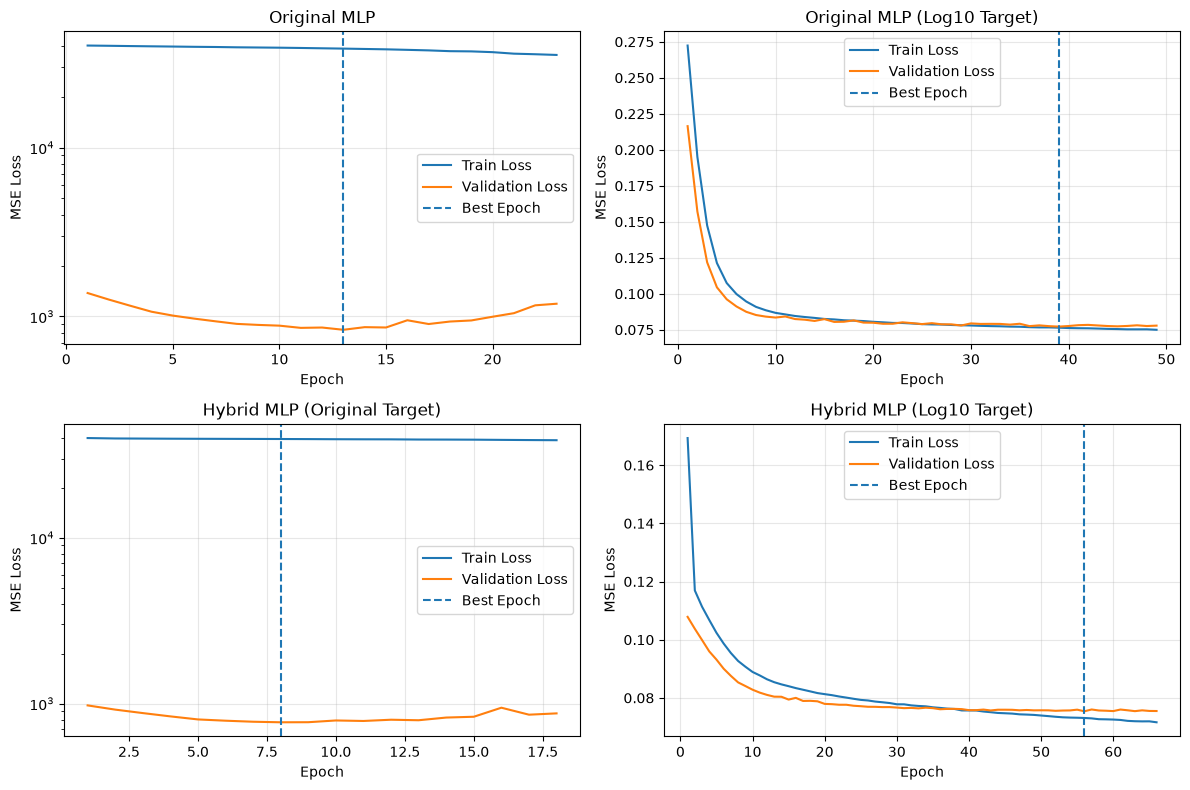

In [67]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

experiments = [
    (train_losses, val_losses, best_epoch,
     "Original MLP"),

    (train_losses_log, val_losses_log, best_epoch_log,
     "Original MLP (Log10 Target)"),

    (train_losses_hybrid, val_losses_hybrid, best_epoch_hybrid,
     "Hybrid MLP (Original Target)"),

    (train_losses_hybrid_log, val_losses_hybrid_log,
     best_epoch_hybrid_log, "Hybrid MLP (Log10 Target)")
]

for ax, (tr, va, be, title) in zip(axes.flatten(), experiments):
    ax.plot(range(1, len(tr) + 1), tr, label="Train Loss")
    ax.plot(range(1, len(va) + 1), va, label="Validation Loss")
    ax.axvline(be, linestyle="--", label="Best Epoch")
    if "Original Target" in title or title == "Original MLP":
        ax.set_yscale("log")   
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

It is unusual to see the curve for Original MLP and Hybrid MLP above. This might be due to the unpresentative train set, meaning that for the train set, there are more extreme values. 

In [68]:
import pandas as pd

summary = pd.DataFrame({
    "Train": pd.Series(y_train).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    ),
    "Validation": pd.Series(y_val).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    ),
    "Test": pd.Series(y_test).describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    )
})

display(summary)

,Train,Validation,Test
count,318339.0000,39792.0000,39793.0000
mean,13.1746,12.3762,12.4455
std,200.7765,37.9873,39.7682
min,1.0000,1.0000,1.0000
50%,6.0000,5.0000,6.0000
90%,24.0000,24.0000,24.0000
95%,36.0000,36.0000,36.0000
99%,120.0000,120.0000,120.0000
99.9%,509.2960,480.0000,547.4880
max,80995.0000,2592.0000,2000.0000


The original-target MLP's unusual training curve is very likely caused by a few extremely large `Quantity` values in the training set. Log the target can make the training more stable. 

## 2(e) 

**What does the embedding layer do?** 
Mathmatically, it is same as one hot encoding followed by a linear layer with no bias. It learns several properties of each item and customer, not just one. Target encoding gives one number per level (the mean). The embedding can place items that are bought in similar quantities by similar customers close together. The network can then model interactions. 

**Why might it be useful in this context?**
Imagine this scenario. A wholesale customer buying a cheap small item orders hundreds of units, while a retail customer buying the same item orders a few. 

We can see embedding layers help a lot based on the evaluation metrics for the test set. 

**Neural Network Performance (Test Set)**

| Model | Target | RMSE ↓ | MAE ↓ | R² ↑ | Huber ↓ |
|---|---|---:|---:|---:|---:|
| Embedding MLP | Original | 30.61 | 8.35 | 0.41 | 7.87 |
| Embedding MLP | Log10 | 29.64 | 5.98 | 0.44 | 5.56 |
| Hybrid MLP | Original | **28.76** | 7.90 | **0.48** | 7.43 |
| Hybrid MLP | Log10 | 31.14 | **5.94** | 0.39 | **5.51** |

**Gradient Boosting Performance (Validation Set, pending confirmation)**

| Model | Loss Function | Target | RMSE ↓ | MAE ↓ | Huber ↓ |
|---|---|---|---:|---:|---:|
| Gradient Boosting | MSE | Original | 28.3583 | 7.5860 | 7.1269 |
| Gradient Boosting | Huber | Original | 28.1771 | 6.7773 | 6.3187 |
| Gradient Boosting | MSE | Log10 | 28.4766 | 6.7289 | 6.2818 |
| Gradient Boosting | Huber | Log10 | **27.5725** | **6.6663** | **6.2207** |

All reported metrics are calculated on the original Quantity scale. Lower RMSE, MAE, and Huber loss indicate better performance, while higher R² indicates better performance.

**Embedding MLP versus Hybrid MLP**

Original target: Hybrid MLP outperforms Embedding MLP across all metrics, achieving lower RMSE (28.76 vs. 30.61) and higher R² (0.48 vs. 0.41).

Log10 target: Embedding MLP achieves better RMSE and R², while Hybrid MLP performs slightly better in MAE and Huber loss.

Overall: Adding target encoding to embeddings does not consistently improve model performance.

**Effect of Log10 Target Transformation**

Embedding MLP: Log10 transformation improves all metrics, reducing RMSE from 30.61 to 29.64 and MAE from 8.35 to 5.98.

Hybrid MLP: Log10 transformation improves MAE (7.90 → 5.94) and Huber loss (7.43 → 5.51), but worsens RMSE (28.76 → 31.14).

Overall: Log10 transformation reduces typical prediction errors but may compromise performance on large target values, particularly for Hybrid MLP.

---
# Problem 3

In [69]:
train =pd.read_csv("train.csv")
train.head()

,x1,x2,y
0,1.1788,-1.2832,1.7520
1,-1.6389,0.3079,-0.6826
2,1.3168,-0.4614,1.0911
3,2.8846,1.1090,0.9186
4,-0.1144,-0.6473,-0.1872


In [70]:
test = pd.read_csv("test.csv")
test.head()

,x1,x2
0,1.5575,-2.8647
1,0.3232,-1.1356
2,1.9937,1.5679
3,-0.0730,-0.1659
4,-2.5611,-1.5920


In [71]:
val = pd.read_csv("val.csv")
val.head()

,x1,x2,y
0,-2.1540,-2.7812,3.2147
1,2.3502,-0.9877,1.2600
2,-1.0178,0.1506,-0.8369
3,-0.4810,-1.2286,0.1201
4,1.2935,1.7530,2.8226


## (a)

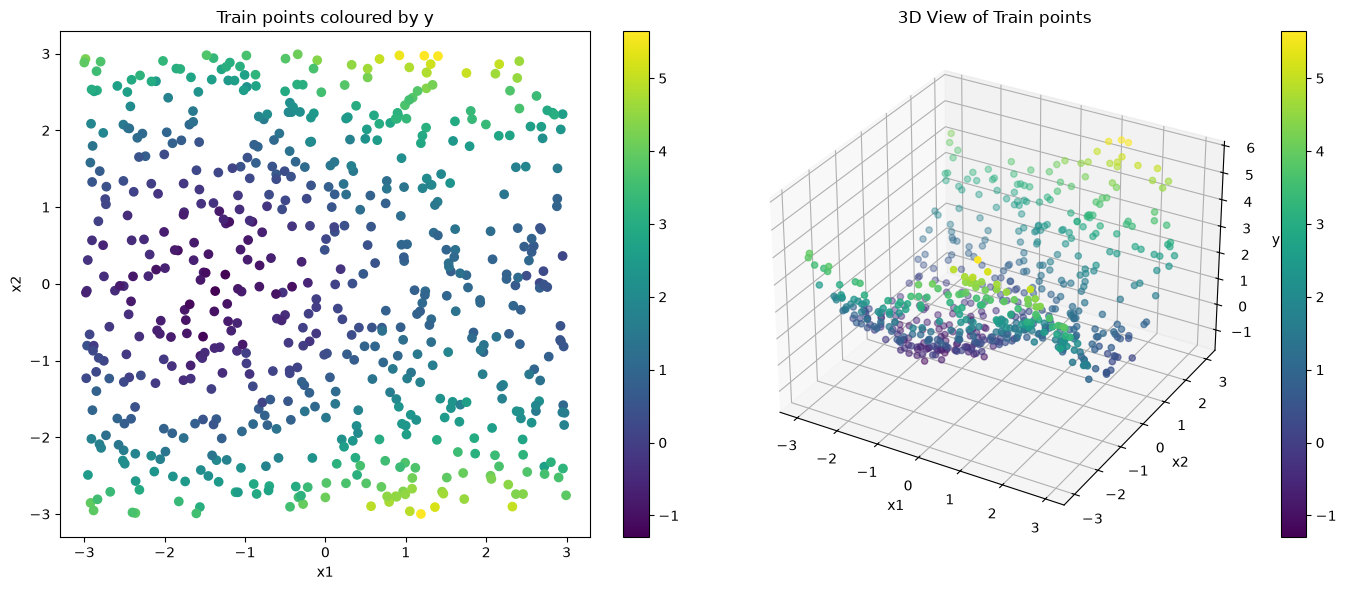

In [72]:
fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(1,2,1)
ax2 = fig.add_subplot(1,2,2, projection='3d')
sc = ax1.scatter(train['x1'], train['x2'], c=train['y'], cmap='viridis')
ax1.set_title('Train points coloured by y')
ax1.set_xlabel('x1')
ax1.set_ylabel('x2')
plt.colorbar(sc, ax=ax1)


ax2.scatter(train['x1'], train['x2'], train['y'], c=train['y'], cmap='viridis')
ax2.set_title('3D View of Train points')
ax2.set_xlabel('x1')
ax2.set_ylabel('x2')
ax2.set_zlabel('y')
plt.colorbar(sc, ax=ax2, orientation='vertical')

plt.tight_layout()
plt.show()

The response surface is smooth and varies slowly. It has a bowl-shaed minimum near (-1.5,0).

## (b) RKS + ridge: sweep over the kernel scale $\sigma$

Fixed number of random features and ridge regularization strength. 
\
Swept: $\sigma \in [0.05, 10]$ (log grid)
\
When $\sigma$ is small, the random weights tend to be larger. The sin/cos functions oscillate more rapidly. There is greater risk of overfitting. 

sigma,0.0500,0.1000,0.2000,0.3000,0.5000,0.7500,1.0000,1.5000,2.0000,3.0000,4.0000,5.0000,7.0000,10.0000
train MSE,0.0000,0.0000,0.0078,0.0160,0.0250,0.0283,0.0291,0.0304,0.0314,0.0326,0.0340,0.0352,0.0363,0.0386
val MSE,4.8896,1.6494,0.5465,0.0664,0.0481,0.0458,0.0434,0.0380,0.0376,0.0366,0.0361,0.0365,0.0371,0.0409


best sigma = 4.0  (val MSE 0.0361)


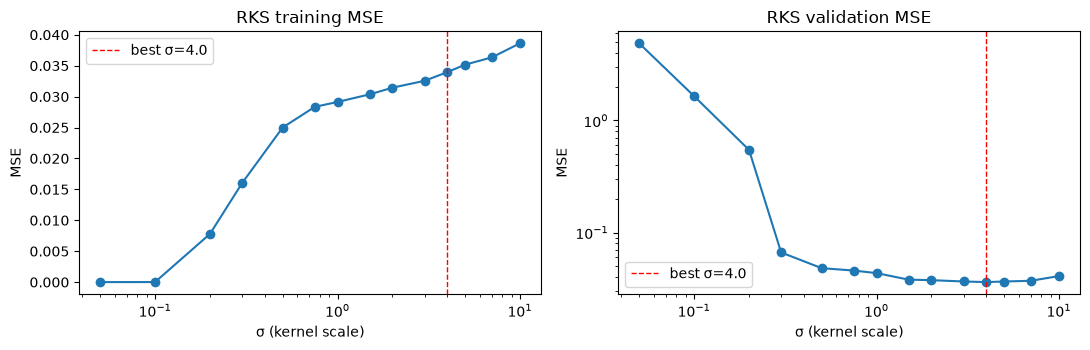

In [73]:
from models import sweep_rks_model
X_train = train[["x1", "x2"]]
X_val = val[["x1", "x2"]]
sigmas = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]
RKS_FIXED = dict(D=1000, ridge_lambda=1e-4, seed=0)
rks_best, rks_best_val, best_sigma, rks_tr, rks_va = sweep_rks_model(
    sigmas, X_train, train["y"], X_val, val["y"], param="sigma", **RKS_FIXED)
display(pd.DataFrame({"sigma": sigmas, "train MSE": rks_tr, "val MSE": rks_va}).set_index("sigma").T)
print(f"best sigma = {best_sigma}  (val MSE {rks_best_val:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, v, t in [(ax[0], rks_tr, "RKS training MSE"), (ax[1], rks_va, "RKS validation MSE")]:
    a.semilogx(sigmas, v, "o-"); a.set(xlabel="σ (kernel scale)", ylabel="MSE", title=t)
    a.axvline(best_sigma, color="r", ls="--", lw=1, label=f"best σ={best_sigma}"); a.legend()
ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

Swept hyper-parameter: $\sigma$ (with D = 1000 and λ = 1e-4 fixed). Best $\sigma$ = 4, validation $MSE = 0.0361$  

## (c)

Fixed: ReLU activation, Adam with lr 3e-3, batch size 64, 1500 epochs, no weight decay, seed 0.
\
Sweept: hidden dimension $\in [1,2,4,...,512]$

hidden,1,2,4,8,16,32,64,128,256,512
train MSE,2.4633,0.2884,0.2884,0.0447,0.0332,0.0297,0.0293,0.0308,0.0321,0.0275
val MSE,2.3967,0.2888,0.2886,0.0466,0.0439,0.0407,0.0397,0.0453,0.0491,0.0438


best hidden width = 64  (val MSE 0.0397)


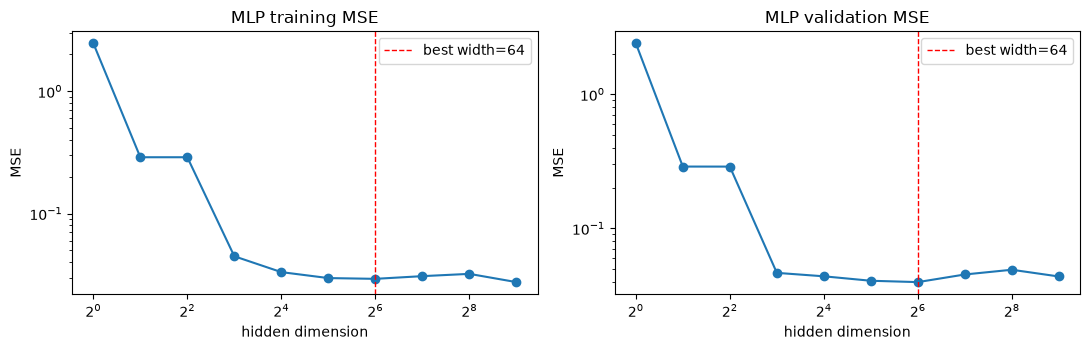

In [74]:
from models import mlp_sweep
widths = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
MLP_FIXED = dict(lr=3e-3, batch_size=64, num_epochs=1500, activation="relu", seed=0)
mlp_best, mlp_best_val, best_width, mlp_tr, mlp_va = mlp_sweep(
    widths, X_train.to_numpy(), train["y"].to_numpy(), X_val.to_numpy(), val["y"].to_numpy(), param="d_hidden", **MLP_FIXED)
display(pd.DataFrame({"hidden": widths, "train MSE": mlp_tr, "val MSE": mlp_va}).set_index("hidden").T)
print(f"best hidden width = {best_width}  (val MSE {mlp_best_val:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, v, t in [(ax[0], mlp_tr, "MLP training MSE"), (ax[1], mlp_va, "MLP validation MSE")]:
    a.semilogx(widths, v, "o-", base=2); a.set(xlabel="hidden dimension", ylabel="MSE", title=t, yscale="log")
    a.axvline(best_width, color="r", ls="--", lw=1, label=f"best width={best_width}"); a.legend()
plt.tight_layout(); plt.show()

## (d)

In [75]:

from models import RandomKitchenSinks, MLP, mse

rks_final = RandomKitchenSinks(**{**RKS_FIXED, "sigma": best_sigma}).fit(X_train.to_numpy(), train["y"].to_numpy()) # Fit the final RKS model with the best sigma
mlp_final = MLP(d_in=2, **{**MLP_FIXED, "d_hidden": best_width}).fit(X_train.to_numpy(), train["y"].to_numpy()) # Fit the final MLP model with the best hidden width

summary3 = pd.DataFrame({
    "best hyper-param": [f"sigma={best_sigma}", f"d_hidden={best_width}"],
    "train MSE": [mse(train["y"], rks_final.predict(X_train.to_numpy())), mse(train["y"], mlp_final.predict(X_train.to_numpy()))],
    "val MSE": [mse(val["y"], rks_final.predict(X_val.to_numpy())), mse(val["y"], mlp_final.predict(X_val.to_numpy()))],
}, index=["RKS (ridge)", "1-hidden-layer MLP"])
display(summary3)

,best hyper-param,train MSE,val MSE
RKS (ridge),sigma=4.0,0.0340,0.0361
1-hidden-layer MLP,d_hidden=64,0.0293,0.0397


In [76]:
X_test = test[["x1", "x2"]].to_numpy()
rks_test = rks_final.predict(X_test)
mlp_test = mlp_final.predict(X_test)
pd.DataFrame({"y": rks_test}).to_csv("rks_test_predictions.csv", index=False)
pd.DataFrame({"y": mlp_test}).to_csv("mlp_test_predictions.csv", index=False)

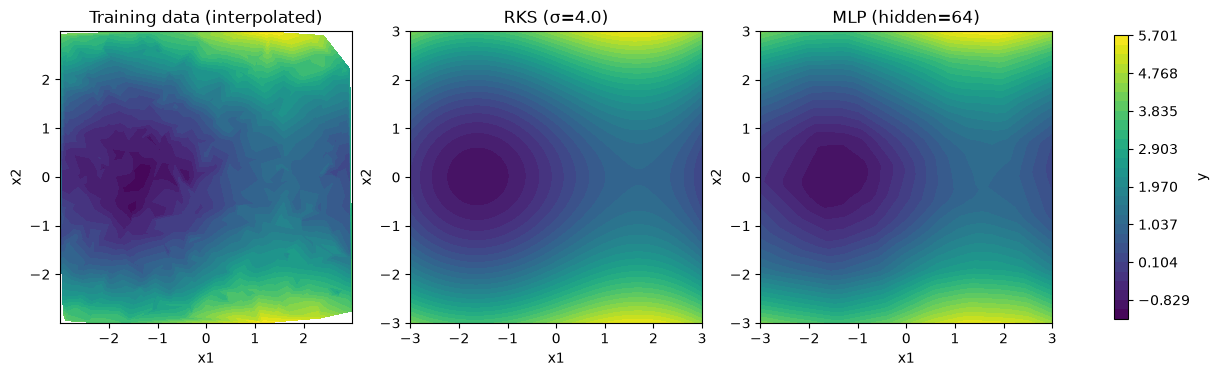

In [77]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

g = np.linspace(-3, 3, 200)
G1, G2 = np.meshgrid(g, g)
Xg = np.c_[G1.ravel(), G2.ravel()]

Zr = np.asarray(rks_final.predict(Xg)).reshape(G1.shape)
Zm = np.asarray(mlp_final.predict(Xg)).reshape(G1.shape)

vmin = min(train["y"].min(), Zr.min(), Zm.min())
vmax = max(train["y"].max(), Zr.max(), Zm.max())
levels = np.linspace(vmin, vmax, 31)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

cf0 = ax[0].tricontourf(
    Triangulation(train["x1"], train["x2"]),
    train["y"],
    levels=levels,
    cmap="viridis"
)
ax[0].set_title("Training data (interpolated)")

ax[1].contourf(
    G1, G2, Zr,
    levels=levels,
    cmap="viridis"
)
ax[1].set_title(f"RKS (σ={best_sigma})")

ax[2].contourf(
    G1, G2, Zm,
    levels=levels,
    cmap="viridis"
)
ax[2].set_title(f"MLP (hidden={best_width})")

for a in ax:
    a.set(
        xlabel="x1",
        ylabel="x2",
        aspect="equal"
    )

fig.colorbar(cf0, ax=ax, label="y", shrink=0.8)

plt.show()

On this problem RKS is slightly better (validation MSE 0.036 vs 0.040), though both are close to the noise floor and the gap is small.
\
The target is a smooth, low-frequency function in 2-D, which is exactly what a Gaussian (RBF) kernel prior assumes. RKS with D = 1000 is an accurate approximation of kernel ridge regression with an RBF kernel of bandwidth σ. With the bandwidth tuned to the data's length-scale, the features already span the right function space, and only a linear layer has to be fit. That fit is a convex problem solved in closed form, with explicit L2 regularisation: no optimisation noise, no local minima, and no sensitivity to the training schedule. Also, we can see the relatively better performance from the figure as well. RKS produces a very smooth surface with round, elliptical contours. 
\
The MLP also learns its features (the first-layer weights), which makes it more adaptive in principle. With only 600 points, though, that flexibility mostly buys a little extra variance: its training MSE (0.029) is lower than RKS's while its validation MSE is higher. It has no explicit regularisation and is trained by non-convex SGD, so its result depends on the seed, learning rate and number of epochs. Learned features pay off in higher dimensions or for functions with sharp or anisotropic structure, which random isotropic features represent inefficiently. That is not the situation here. From the figure, MLP proudces a surface that is piecewise linear. 